In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

In [3]:
file_path = "../data/Delinquency_prediction_dataset.xlsx"

df = pd.read_excel(file_path)

print("Dataset successfully loaded.")
print("Dataset shape:", df.shape)

display(df.head())

Dataset successfully loaded.
Dataset shape: (500, 19)


,Customer_ID,Age,Income,Credit_Score,Credit_Utilization,Missed_Payments,Delinquent_Account,Loan_Balance,Debt_to_Income_Ratio,Employment_Status,Account_Tenure,Credit_Card_Type,Location,Month_1,Month_2,Month_3,Month_4,Month_5,Month_6
0,CUST0001,56,165580,398.0,0.390502,3,0,16310.0,0.317396,Employed,18,Student,Los Angeles,Late,Late,Missed,Late,Missed,Late
1,CUST0002,69,100999,493.0,0.312444,6,1,17401.0,0.196093,Self-Employed,0,Standard,Phoenix,Missed,Missed,Late,Missed,On-time,On-time
2,CUST0003,46,188416,500.0,0.359930,0,0,13761.0,0.301655,Self-Employed,1,Platinum,Chicago,Missed,Late,Late,On-time,Missed,Late
3,CUST0004,32,101672,413.0,0.371400,3,0,88778.0,0.264794,UnEmployed,15,Platinum,Phoenix,Late,Missed,Late,Missed,Late,Late
4,CUST0005,60,38524,487.0,0.234716,2,0,13316.0,0.510583,Self-Employed,11,Standard,Phoenix,Missed,On-time,Missed,Late,Late,Late


In [4]:
print("Dataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:", df.duplicated().sum())

print("\nStatistical Summary:")
display(df.describe())

print("\nTarget Variable Distribution:")
print(df["Delinquent_Account"].value_counts())

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 19 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Customer_ID           500 non-null    str    
 1   Age                   500 non-null    int64  
 2   Income                500 non-null    int64  
 3   Credit_Score          500 non-null    float64
 4   Credit_Utilization    500 non-null    float64
 5   Missed_Payments       500 non-null    int64  
 6   Delinquent_Account    500 non-null    int64  
 7   Loan_Balance          500 non-null    float64
 8   Debt_to_Income_Ratio  500 non-null    float64
 9   Employment_Status     500 non-null    str    
 10  Account_Tenure        500 non-null    int64  
 11  Credit_Card_Type      500 non-null    str    
 12  Location              500 non-null    str    
 13  Month_1               500 non-null    str    
 14  Month_2               500 non-null    str    
 15  Month_3      

,Age,Income,Credit_Score,Credit_Utilization,Missed_Payments,Delinquent_Account,Loan_Balance,Debt_to_Income_Ratio,Account_Tenure
count,500.000000,500.000000,500.000000,500.000000,500.000000,500.000000,500.000000,500.000000,500.000000
mean,46.266000,109193.228000,576.975000,0.491446,2.968000,0.160000,48712.809000,0.298862,9.740000
std,16.187629,53516.368812,168.954915,0.197103,1.946935,0.366973,29565.751522,0.094521,5.923054
min,18.000000,15404.000000,301.000000,0.050000,0.000000,0.000000,612.000000,0.100000,0.000000
25%,33.000000,65439.500000,415.750000,0.356486,1.000000,0.000000,23685.000000,0.233639,5.000000
50%,46.500000,108610.000000,584.000000,0.485636,3.000000,0.000000,46691.500000,0.301634,10.000000
75%,59.250000,155783.500000,725.750000,0.634440,5.000000,0.000000,75431.250000,0.362737,15.000000
max,74.000000,199943.000000,847.000000,1.025843,6.000000,1.000000,99620.000000,0.552956,19.000000



Target Variable Distribution:
Delinquent_Account
0    420
1     80
Name: count, dtype: int64


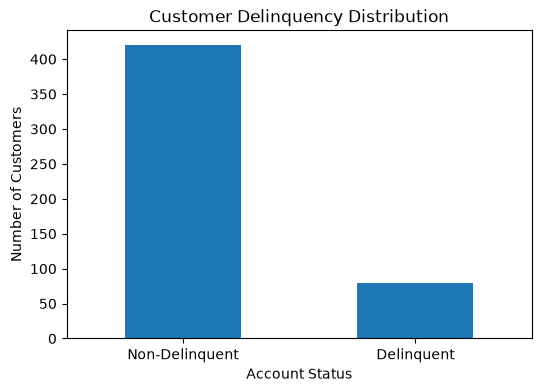

In [5]:
# Distribution of delinquent and non-delinquent accounts

df["Delinquent_Account"].value_counts().sort_index().plot(
    kind="bar",
    figsize=(6, 4)
)

plt.title("Customer Delinquency Distribution")
plt.xlabel("Account Status")
plt.ylabel("Number of Customers")
plt.xticks([0, 1], ["Non-Delinquent", "Delinquent"], rotation=0)
plt.show()

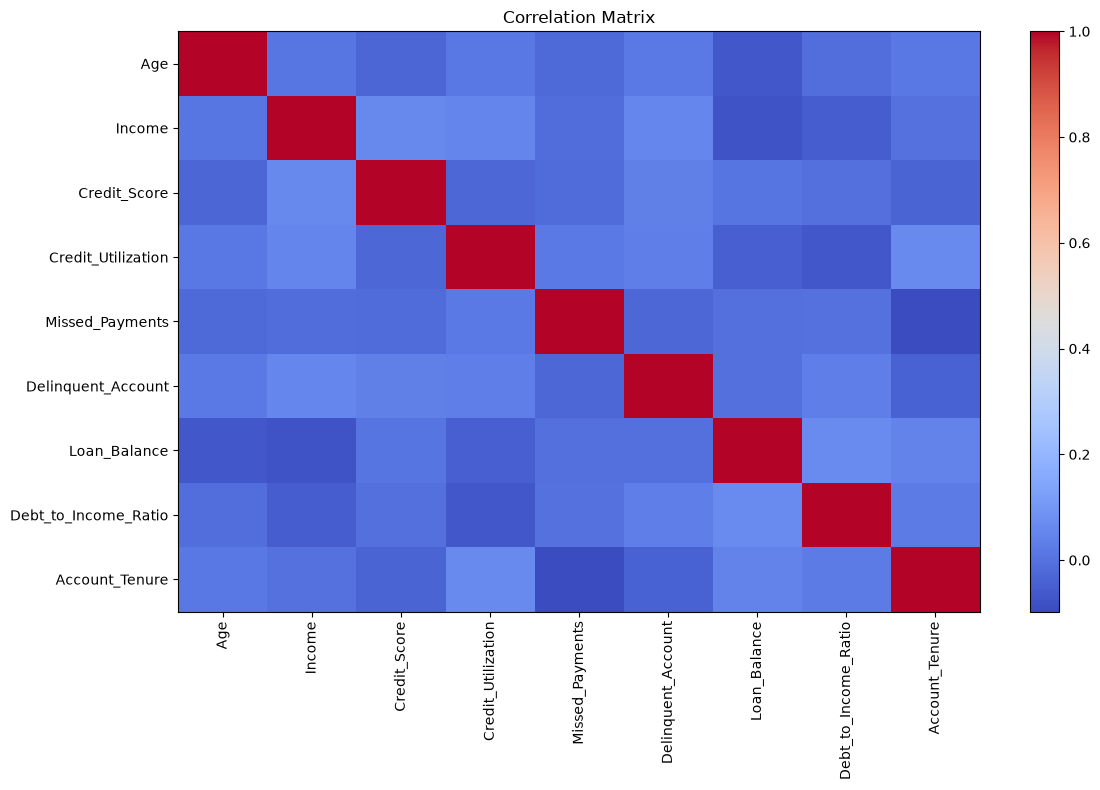

In [6]:
# Correlation between numerical variables

correlation = df.select_dtypes(include=np.number).corr()

plt.figure(figsize=(12, 8))
plt.imshow(correlation, cmap="coolwarm", aspect="auto")
plt.colorbar()

plt.xticks(range(len(correlation.columns)), correlation.columns,
           rotation=90)
plt.yticks(range(len(correlation.columns)), correlation.columns)

plt.title("Correlation Matrix")
plt.tight_layout()
plt.show()

In [7]:
features = [
    "Income",
    "Credit_Utilization",
    "Debt_to_Income_Ratio",
    "Missed_Payments"
]

target = "Delinquent_Account"

X = df[features]
y = df[target]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training records:", X_train.shape[0])
print("Testing records:", X_test.shape[0])

Training records: 400
Testing records: 100


In [8]:
# Decision Tree

decision_tree = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", DecisionTreeClassifier(
        max_depth=3,
        min_samples_leaf=10,
        class_weight="balanced",
        random_state=42
    ))
])

decision_tree.fit(X_train, y_train)


# Logistic Regression

logistic_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(
        class_weight="balanced",
        max_iter=1000,
        random_state=42
    ))
])

logistic_model.fit(X_train, y_train)


# Neural Network

neural_network = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", MLPClassifier(
        hidden_layer_sizes=(16, 8),
        max_iter=1000,
        random_state=42
    ))
])

neural_network.fit(X_train, y_train)

print("All three models have been trained.")

All three models have been trained.


C:\Users\gurug\anaconda3\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  warnings.warn(


In [9]:
models = {
    "Decision Tree": decision_tree,
    "Logistic Regression": logistic_model,
    "Neural Network": neural_network
}

results = []

for name, model in models.items():

    predictions = model.predict(X_test)
    probabilities = model.predict_proba(X_test)[:, 1]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions, zero_division=0),
        "Recall": recall_score(y_test, predictions, zero_division=0),
        "F1 Score": f1_score(y_test, predictions, zero_division=0),
        "AUC-ROC": roc_auc_score(y_test, probabilities)
    })

results_df = pd.DataFrame(results)

display(results_df.round(3))

,Model,Accuracy,Precision,Recall,F1 Score,AUC-ROC
0,Decision Tree,0.46,0.135,0.438,0.206,0.465
1,Logistic Regression,0.47,0.106,0.312,0.159,0.423
2,Neural Network,0.73,0.077,0.062,0.069,0.427



 Decision Tree
Confusion Matrix:
[[39 45]
 [ 9  7]]

Classification Report:
              precision    recall  f1-score   support

           0       0.81      0.46      0.59        84
           1       0.13      0.44      0.21        16

    accuracy                           0.46       100
   macro avg       0.47      0.45      0.40       100
weighted avg       0.70      0.46      0.53       100



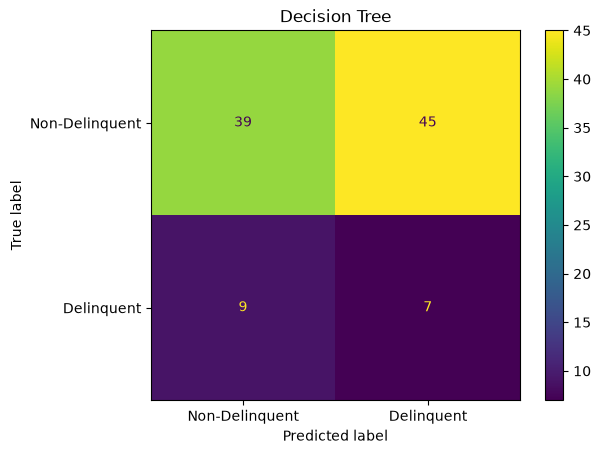


 Logistic Regression
Confusion Matrix:
[[42 42]
 [11  5]]

Classification Report:
              precision    recall  f1-score   support

           0       0.79      0.50      0.61        84
           1       0.11      0.31      0.16        16

    accuracy                           0.47       100
   macro avg       0.45      0.41      0.39       100
weighted avg       0.68      0.47      0.54       100



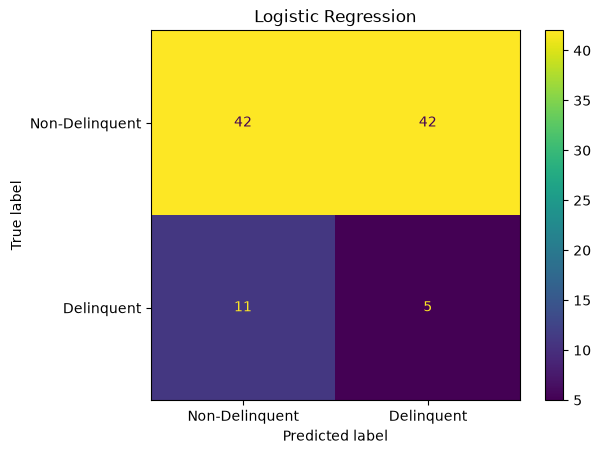


 Neural Network
Confusion Matrix:
[[72 12]
 [15  1]]

Classification Report:
              precision    recall  f1-score   support

           0       0.83      0.86      0.84        84
           1       0.08      0.06      0.07        16

    accuracy                           0.73       100
   macro avg       0.45      0.46      0.46       100
weighted avg       0.71      0.73      0.72       100



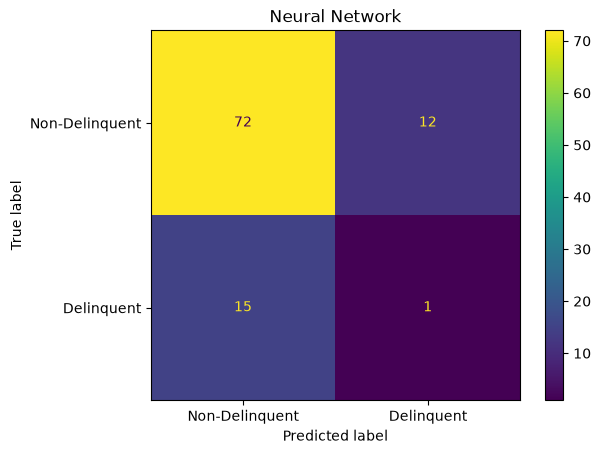

In [10]:
for name, model in models.items():

    predictions = model.predict(X_test)

    print("\n", name)
    print("Confusion Matrix:")
    print(confusion_matrix(y_test, predictions))

    print("\nClassification Report:")
    print(classification_report(
        y_test,
        predictions,
        zero_division=0
    ))

    ConfusionMatrixDisplay.from_predictions(
        y_test,
        predictions,
        display_labels=["Non-Delinquent", "Delinquent"]
    )

    plt.title(name)
    plt.show()

In [11]:
# Generate predictions using the Decision Tree model

fairness_data = X_test.copy()

fairness_data["Actual"] = y_test
fairness_data["Predicted"] = decision_tree.predict(X_test)
fairness_data["Age"] = df.loc[X_test.index, "Age"]

# Divide customers into age groups

fairness_data["Age_Group"] = pd.cut(
    fairness_data["Age"],
    bins=[17, 29, 44, 59, 74],
    labels=["18-29", "30-44", "45-59", "60-74"]
)

fairness_results = []

for group, data in fairness_data.groupby("Age_Group", observed=True):

    actual = data["Actual"]
    predicted = data["Predicted"]

    tn, fp, fn, tp = confusion_matrix(
        actual,
        predicted,
        labels=[0, 1]
    ).ravel()

    fairness_results.append({
        "Age Group": group,
        "Customer Count": len(data),
        "Predicted High Risk (%)": round(predicted.mean() * 100, 2),
        "Recall (%)": round(tp / (tp + fn) * 100, 2)
        if (tp + fn) > 0 else 0,
        "False Positive Rate (%)": round(fp / (fp + tn) * 100, 2)
        if (fp + tn) > 0 else 0
    })

fairness_df = pd.DataFrame(fairness_results)

display(fairness_df)

,Age Group,Customer Count,Predicted High Risk (%),Recall (%),False Positive Rate (%)
0,18-29,24,62.50,60.00,63.16
1,30-44,26,42.31,25.00,45.45
2,45-59,20,50.00,0.00,50.00
3,60-74,30,53.33,42.86,56.52


In [12]:
results_df.to_csv("model_evaluation_results.csv", index=False)

fairness_df.to_csv("fairness_analysis_results.csv", index=False)

print("Evaluation and fairness results saved successfully.")

Evaluation and fairness results saved successfully.
